# IndoBERT Fully-Connected

In [1]:
import pandas as pd
import ast
import re
import torch
import torch.nn as nn
import time
from tqdm import tqdm
from sklearn.model_selection import KFold
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
from datetime import datetime
import os
from sklearn.model_selection import StratifiedKFold
from transformers import get_linear_schedule_with_warmup
import copy
import numpy as np

c:\Users\Lenovo\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load Dataset

In [2]:
df = pd.read_csv("dataset-final.csv")

def extract_label(x):
    if pd.isna(x):
        return None

    if isinstance(x, list):
        return str(x[0]).strip() if len(x) > 0 else None

    x = str(x).strip()

    if x.startswith("[") and x.endswith("]"):
        try:
            labels = ast.literal_eval(x)
            if isinstance(labels, list) and len(labels) > 0:
                return str(labels[0]).strip()
        except Exception:
            pass

    return x

df["label"] = df["dominant_label"].apply(extract_label)

df["label"] = (
    df["label"]
    .astype(str)
    .str.strip()
)

CLASS_NAMES = sorted(df["label"].unique())

LABEL_MAP = {
    label: idx
    for idx, label in enumerate(CLASS_NAMES)
}

df["label"] = df["label"].map(LABEL_MAP)

NUM_CLASSES = len(CLASS_NAMES)

print("Jumlah kelas:", NUM_CLASSES)
print("Class names :", CLASS_NAMES)

Jumlah kelas: 5
Class names : ['Body Shaming', 'Denigration', 'Flaming', 'Harassment', 'Neutral']


## Preprocessing

In [3]:
df = df.dropna(subset=["text"])

df["text"] = df["text"].astype(str)


def clean_text(text):
    text = text.lower()
    text = re.sub(r'\busername\b', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'http\S+|www\.\S+', '', text)
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'[^a-zA-Z\s!?]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text


df["text"] = df["text"].apply(clean_text)

texts = df["text"].tolist()
labels = df["label"].tolist()

## Tokenizer

In [4]:
tokenizer = AutoTokenizer.from_pretrained("indobenchmark/indobert-base-p2")

In [5]:
lengths = [
    len(tokenizer.tokenize(text))
    for text in df["text"]
]

print(max(lengths))
print(np.mean(lengths))
print(np.median(lengths))
print(np.percentile(lengths, 95))

202
12.8396
10.0
31.0


## Dataset Class

In [6]:
class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = tokenizer(
            self.texts[idx],
            truncation=True,
            padding='max_length',
            max_length=128,
            return_tensors='pt'
        )

        return {
            'input_ids': encoding['input_ids'].squeeze(),
            'attention_mask': encoding['attention_mask'].squeeze(),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long),
            'text': self.texts[idx]
        }

## Model

In [7]:
class IndoBERTClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.bert = AutoModel.from_pretrained("indobenchmark/indobert-base-p2")
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(768, NUM_CLASSES)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls_output = outputs.last_hidden_state[:, 0, :]
        x = self.dropout(cls_output)
        logits = self.fc(x)
        return logits

## Konfigurasi

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CONFIG = {
    "epochs": 5,
    "batch_size": 32,
    "lr": 2e-5,          
    "weight_decay": 0.01,
    "warmup_ratio": 0.1,
    "max_grad_norm": 1.0,
    "patience": 2,
    "n_splits": 5,
    "random_state": 42
}

LEARNING_RATES = [
    2e-5,
    3e-5
]

kf = StratifiedKFold(
    n_splits=CONFIG["n_splits"],
    shuffle=True,
    random_state=CONFIG["random_state"]
)

def setup_model(device, lr):
    model = IndoBERTClassifier().to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=CONFIG["weight_decay"]
    )

    criterion = nn.CrossEntropyLoss()

    return model, optimizer, criterion

## Training 

In [9]:
def train_one_epoch(model, loader, optimizer, scheduler, criterion, device):
    model.train()
    total_loss = 0

    for batch in loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()

        outputs = model(input_ids, attention_mask)

        loss = criterion(outputs, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            CONFIG["max_grad_norm"]
        )

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

    return total_loss / len(loader)

## Validation

In [10]:
def evaluate(model, loader, device):
    model.eval()
    all_preds, all_labels, all_texts, all_probs = [], [], [], []

    with torch.no_grad():
        for batch in loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            outputs = model(input_ids, attention_mask)

            probs = torch.softmax(outputs, dim=1)
            preds = torch.argmax(probs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
            all_texts.extend(batch['text'])

    return all_preds, all_labels, all_texts, all_probs

## Main Loop


EKSPERIMEN LEARNING RATE = 2e-05


===== FOLD 1 =====
Learning Rate: 2e-05 | Fold 1/5
Epoch 1 | Loss: 1.3582 | Acc: 0.5800
Epoch 2 | Loss: 0.8186 | Acc: 0.6840
Epoch 3 | Loss: 0.4866 | Acc: 0.6800
Epoch 4 | Loss: 0.2772 | Acc: 0.7040
Epoch 5 | Loss: 0.1725 | Acc: 0.7000

=== METRICS ===
Accuracy : 0.7040
Precision: 0.7069
Recall   : 0.7040
F1 Score : 0.7028

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

Body Shaming       0.83      0.70      0.76        98
 Denigration       0.70      0.63      0.67       109
     Flaming       0.62      0.62      0.62        52
  Harassment       0.48      0.48      0.48        44
     Neutral       0.72      0.82      0.77       197

    accuracy                           0.70       500
   macro avg       0.67      0.65      0.66       500
weighted avg       0.71      0.70      0.70       500


Confusion Matrix:
[[ 69   8   5   0  16]
 [  3  69   8   6  23]
 [  1   2  32   7  10]
 [  1   4   5  21  13]
 [  9  1

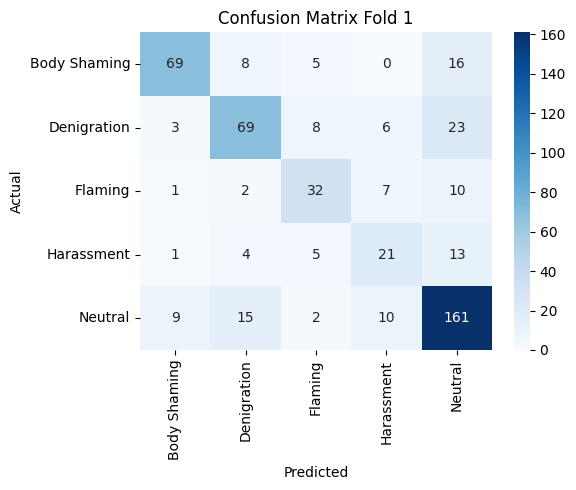


===== FOLD 2 =====
Learning Rate: 2e-05 | Fold 2/5
Epoch 1 | Loss: 1.3326 | Acc: 0.5900
Epoch 2 | Loss: 0.8188 | Acc: 0.6560
Epoch 3 | Loss: 0.4857 | Acc: 0.6720
Epoch 4 | Loss: 0.2792 | Acc: 0.6740
Epoch 5 | Loss: 0.1728 | Acc: 0.6840

=== METRICS ===
Accuracy : 0.6840
Precision: 0.6813
Recall   : 0.6840
F1 Score : 0.6773

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

Body Shaming       0.79      0.69      0.74        99
 Denigration       0.68      0.60      0.63       109
     Flaming       0.64      0.54      0.58        52
  Harassment       0.47      0.36      0.41        44
     Neutral       0.69      0.84      0.76       196

    accuracy                           0.68       500
   macro avg       0.65      0.61      0.62       500
weighted avg       0.68      0.68      0.68       500


Confusion Matrix:
[[ 68   5   4   1  21]
 [  9  65   3   4  28]
 [  3   7  28   6   8]
 [  1   5   4  16  18]
 [  5  14   5   7 165]]


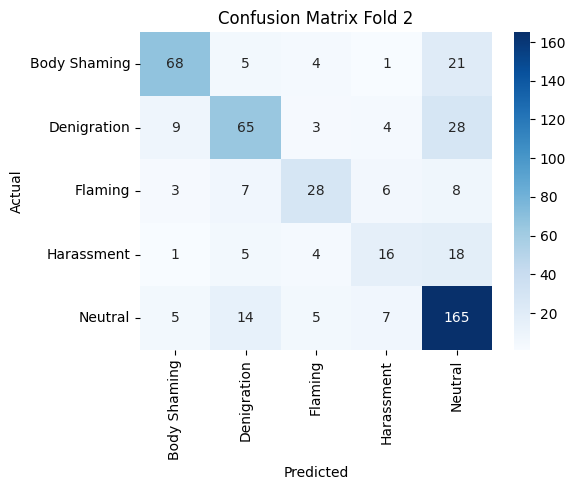


===== FOLD 3 =====
Learning Rate: 2e-05 | Fold 3/5
Epoch 1 | Loss: 1.3535 | Acc: 0.6020
Epoch 2 | Loss: 0.8415 | Acc: 0.7140
Epoch 3 | Loss: 0.5254 | Acc: 0.7320
Epoch 4 | Loss: 0.3091 | Acc: 0.7400
Epoch 5 | Loss: 0.1983 | Acc: 0.7440

=== METRICS ===
Accuracy : 0.7440
Precision: 0.7429
Recall   : 0.7440
F1 Score : 0.7424

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

Body Shaming       0.77      0.77      0.77        99
 Denigration       0.72      0.70      0.71       109
     Flaming       0.77      0.65      0.71        52
  Harassment       0.61      0.57      0.59        44
     Neutral       0.77      0.82      0.79       196

    accuracy                           0.74       500
   macro avg       0.73      0.70      0.71       500
weighted avg       0.74      0.74      0.74       500


Confusion Matrix:
[[ 76   9   3   0  11]
 [  7  76   3   4  19]
 [  2   4  34   7   5]
 [  3   0   2  25  14]
 [ 11  17   2   5 161]]


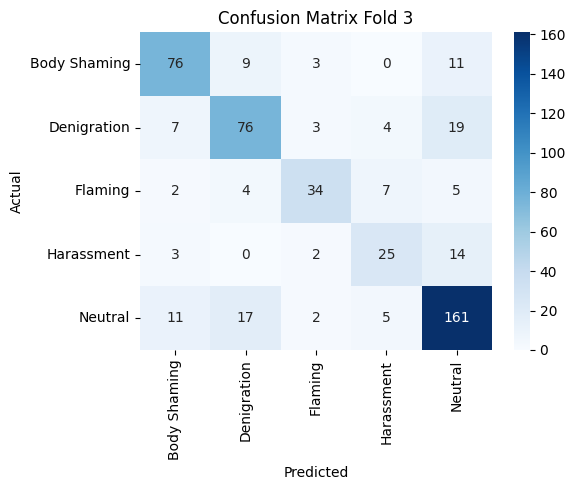


===== FOLD 4 =====
Learning Rate: 2e-05 | Fold 4/5
Epoch 1 | Loss: 1.3859 | Acc: 0.5720
Epoch 2 | Loss: 0.8176 | Acc: 0.6580
Epoch 3 | Loss: 0.4704 | Acc: 0.6560
Epoch 4 | Loss: 0.2622 | Acc: 0.6620
Epoch 5 | Loss: 0.1511 | Acc: 0.6680

=== METRICS ===
Accuracy : 0.6680
Precision: 0.6744
Recall   : 0.6680
F1 Score : 0.6700

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

Body Shaming       0.80      0.79      0.79        98
 Denigration       0.52      0.61      0.56       109
     Flaming       0.66      0.56      0.60        52
  Harassment       0.47      0.47      0.47        45
     Neutral       0.75      0.72      0.73       196

    accuracy                           0.67       500
   macro avg       0.64      0.63      0.63       500
weighted avg       0.67      0.67      0.67       500


Confusion Matrix:
[[ 77   8   1   1  11]
 [  6  66   7   4  26]
 [  2   9  29   9   3]
 [  1  12   3  21   8]
 [ 10  31   4  10 141]]


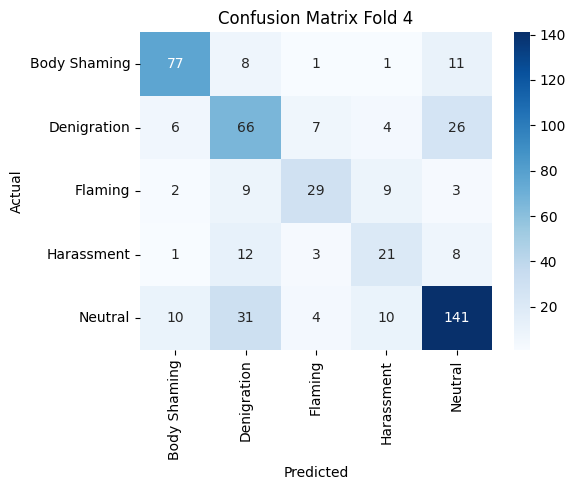


===== FOLD 5 =====
Learning Rate: 2e-05 | Fold 5/5
Epoch 1 | Loss: 1.4014 | Acc: 0.5980
Epoch 2 | Loss: 0.8507 | Acc: 0.6760
Epoch 3 | Loss: 0.4990 | Acc: 0.6920
Epoch 4 | Loss: 0.2858 | Acc: 0.6980
Epoch 5 | Loss: 0.1799 | Acc: 0.7080

=== METRICS ===
Accuracy : 0.7080
Precision: 0.7064
Recall   : 0.7080
F1 Score : 0.7065

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

Body Shaming       0.74      0.83      0.78        98
 Denigration       0.64      0.60      0.62       108
     Flaming       0.65      0.65      0.65        52
  Harassment       0.53      0.51      0.52        45
     Neutral       0.78      0.77      0.77       197

    accuracy                           0.71       500
   macro avg       0.67      0.67      0.67       500
weighted avg       0.71      0.71      0.71       500


Confusion Matrix:
[[ 81   4   4   1   8]
 [  7  65   9   6  21]
 [  6   7  34   4   1]
 [  1   6   3  23  12]
 [ 15  20   2   9 151]]


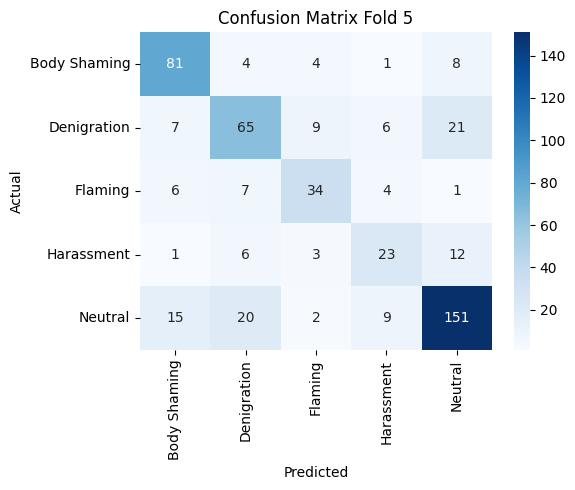


EKSPERIMEN LEARNING RATE = 3e-05


===== FOLD 1 =====
Learning Rate: 3e-05 | Fold 1/5
Epoch 1 | Loss: 1.3383 | Acc: 0.6000
Epoch 2 | Loss: 0.7509 | Acc: 0.6820
Epoch 3 | Loss: 0.3585 | Acc: 0.7200
Epoch 4 | Loss: 0.1517 | Acc: 0.7160
Epoch 5 | Loss: 0.0575 | Acc: 0.7200
Early stopping triggered.

=== METRICS ===
Accuracy : 0.7200
Precision: 0.7234
Recall   : 0.7200
F1 Score : 0.7211

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

Body Shaming       0.80      0.80      0.80        98
 Denigration       0.63      0.70      0.66       109
     Flaming       0.70      0.63      0.67        52
  Harassment       0.47      0.48      0.47        44
     Neutral       0.80      0.77      0.79       197

    accuracy                           0.72       500
   macro avg       0.68      0.68      0.68       500
weighted avg       0.72      0.72      0.72       500


Confusion Matrix:
[[ 78   9   3   1   7]
 [  4  76   7   7  15]
 [  1   5  33   7   6]
 [  3

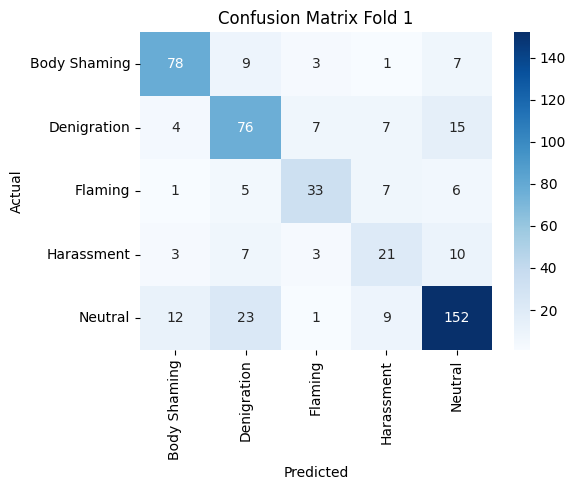


===== FOLD 2 =====
Learning Rate: 3e-05 | Fold 2/5
Epoch 1 | Loss: 1.2952 | Acc: 0.6340
Epoch 2 | Loss: 0.7297 | Acc: 0.6720
Epoch 3 | Loss: 0.3494 | Acc: 0.6900
Epoch 4 | Loss: 0.1406 | Acc: 0.6940
Epoch 5 | Loss: 0.0541 | Acc: 0.7020

=== METRICS ===
Accuracy : 0.7020
Precision: 0.7079
Recall   : 0.7020
F1 Score : 0.7008

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

Body Shaming       0.81      0.72      0.76        99
 Denigration       0.68      0.61      0.65       109
     Flaming       0.79      0.60      0.68        52
  Harassment       0.49      0.52      0.51        44
     Neutral       0.70      0.81      0.75       196

    accuracy                           0.70       500
   macro avg       0.69      0.65      0.67       500
weighted avg       0.71      0.70      0.70       500


Confusion Matrix:
[[ 71   5   2   1  20]
 [  8  67   2   4  28]
 [  2   7  31   5   7]
 [  1   3   3  23  14]
 [  6  16   1  14 159]]


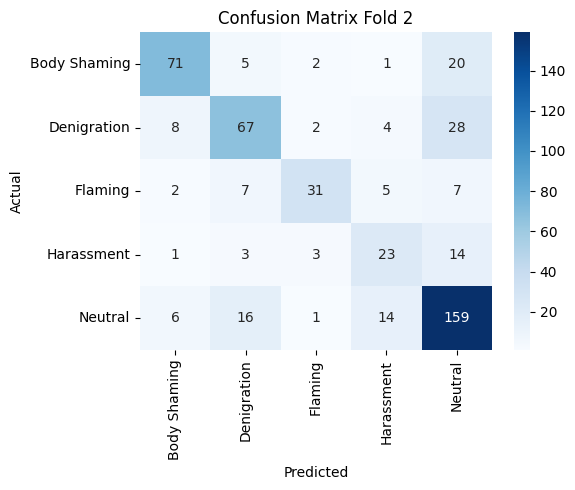


===== FOLD 3 =====
Learning Rate: 3e-05 | Fold 3/5
Epoch 1 | Loss: 1.3350 | Acc: 0.6200
Epoch 2 | Loss: 0.7556 | Acc: 0.6940
Epoch 3 | Loss: 0.3759 | Acc: 0.7200
Epoch 4 | Loss: 0.1577 | Acc: 0.7260
Epoch 5 | Loss: 0.0524 | Acc: 0.7360

=== METRICS ===
Accuracy : 0.7360
Precision: 0.7377
Recall   : 0.7360
F1 Score : 0.7356

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

Body Shaming       0.80      0.82      0.81        99
 Denigration       0.74      0.72      0.73       109
     Flaming       0.73      0.58      0.65        52
  Harassment       0.49      0.55      0.52        44
     Neutral       0.76      0.79      0.78       196

    accuracy                           0.74       500
   macro avg       0.70      0.69      0.69       500
weighted avg       0.74      0.74      0.74       500


Confusion Matrix:
[[ 81   5   2   1  10]
 [  4  78   4   4  19]
 [  4   3  30   9   6]
 [  2   1   4  24  13]
 [ 10  19   1  11 155]]


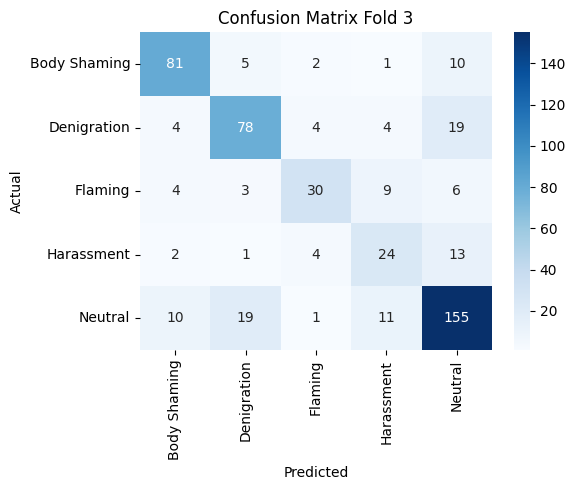


===== FOLD 4 =====
Learning Rate: 3e-05 | Fold 4/5
Epoch 1 | Loss: 1.3736 | Acc: 0.6020
Epoch 2 | Loss: 0.7527 | Acc: 0.6600
Epoch 3 | Loss: 0.3388 | Acc: 0.6680
Epoch 4 | Loss: 0.1339 | Acc: 0.6820
Epoch 5 | Loss: 0.0455 | Acc: 0.6820

=== METRICS ===
Accuracy : 0.6820
Precision: 0.6913
Recall   : 0.6820
F1 Score : 0.6828

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

Body Shaming       0.79      0.83      0.81        98
 Denigration       0.53      0.67      0.59       109
     Flaming       0.65      0.63      0.64        52
  Harassment       0.43      0.33      0.38        45
     Neutral       0.81      0.71      0.76       196

    accuracy                           0.68       500
   macro avg       0.64      0.63      0.63       500
weighted avg       0.69      0.68      0.68       500


Confusion Matrix:
[[ 81   9   0   0   8]
 [  8  73   7   5  16]
 [  4   7  33   6   2]
 [  1  15   7  15   7]
 [  9  35   4   9 139]]


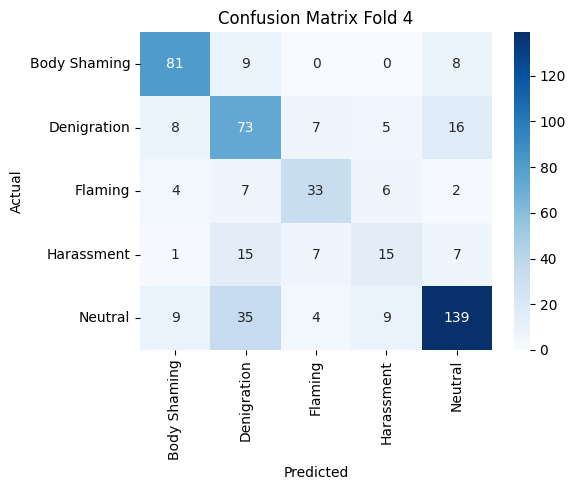


===== FOLD 5 =====
Learning Rate: 3e-05 | Fold 5/5
Epoch 1 | Loss: 1.3113 | Acc: 0.6540
Epoch 2 | Loss: 0.7294 | Acc: 0.6920
Epoch 3 | Loss: 0.3493 | Acc: 0.7140
Epoch 4 | Loss: 0.1358 | Acc: 0.7220
Epoch 5 | Loss: 0.0541 | Acc: 0.7480

=== METRICS ===
Accuracy : 0.7480
Precision: 0.7470
Recall   : 0.7480
F1 Score : 0.7467

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

Body Shaming       0.80      0.82      0.81        98
 Denigration       0.71      0.62      0.66       108
     Flaming       0.81      0.81      0.81        52
  Harassment       0.57      0.60      0.59        45
     Neutral       0.77      0.80      0.78       197

    accuracy                           0.75       500
   macro avg       0.73      0.73      0.73       500
weighted avg       0.75      0.75      0.75       500


Confusion Matrix:
[[ 80   4   1   1  12]
 [  8  67   5   6  22]
 [  2   4  42   3   1]
 [  0   4   1  27  13]
 [ 10  16   3  10 158]]


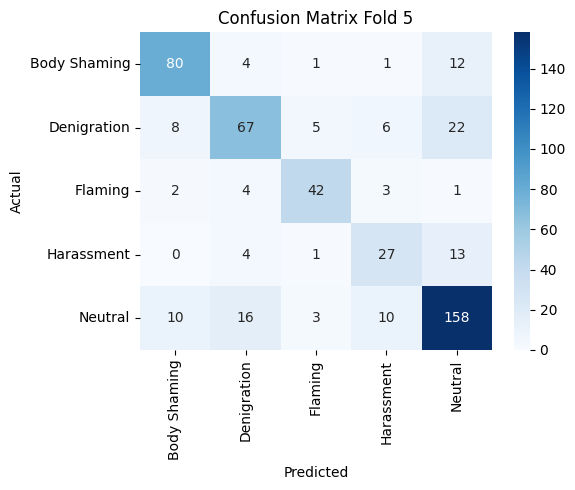

In [11]:
def run_cross_validation(lr):
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    output_dir = f"cv_results_lr_{lr}_{timestamp}"
    os.makedirs(output_dir, exist_ok=True)

    for fold, (train_idx, val_idx) in enumerate(kf.split(texts, labels)):
        print(f"\n===== FOLD {fold+1} =====")
        print(f"Learning Rate: {lr} | Fold {fold+1}/{CONFIG['n_splits']}")

        train_dataset = TextDataset(
            [texts[i] for i in train_idx],
            [labels[i] for i in train_idx]
        )

        val_dataset = TextDataset(
            [texts[i] for i in val_idx],
            [labels[i] for i in val_idx]
        )

        train_loader = DataLoader(
            train_dataset,
            batch_size=CONFIG["batch_size"],
            shuffle=True
        )

        val_loader = DataLoader(
            val_dataset,
            batch_size=CONFIG["batch_size"]
        )

        model, optimizer, criterion = setup_model(device, lr)

        total_steps = len(train_loader) * CONFIG["epochs"]

        scheduler = get_linear_schedule_with_warmup(
            optimizer,
            num_warmup_steps=int(CONFIG["warmup_ratio"] * total_steps),
            num_training_steps=total_steps
        )

        best_acc = 0
        best_model = None
        patience_counter = 0

        for epoch in range(CONFIG["epochs"]):

            loss = train_one_epoch(
                model,
                train_loader,
                optimizer,
                scheduler,
                criterion,
                device
            )

            preds, labels_true, texts_val, probs = evaluate(
                model,
                val_loader,
                device
            )

            acc = accuracy_score(labels_true, preds)

            print(
                f"Epoch {epoch+1} | Loss: {loss:.4f} | Acc: {acc:.4f}"
            )

            if acc > best_acc:
                best_acc = acc
                best_model = copy.deepcopy(model.state_dict())
                patience_counter = 0
            else:
                patience_counter += 1

            if patience_counter >= CONFIG["patience"]:
                print("Early stopping triggered.")
                break

        model.load_state_dict(best_model)

        preds, labels_true, texts_val, probs = evaluate(
            model,
            val_loader,
            device
        )

        acc = accuracy_score(labels_true, preds)
        precision = precision_score(
            labels_true,
            preds,
            average="weighted",
            zero_division=0
        )

        recall = recall_score(
            labels_true,
            preds,
            average="weighted",
            zero_division=0
        )

        f1 = f1_score(
            labels_true,
            preds,
            average="weighted",
            zero_division=0
        )

        print("\n=== METRICS ===")
        print(f"Accuracy : {acc:.4f}")
        print(f"Precision: {precision:.4f}")
        print(f"Recall   : {recall:.4f}")
        print(f"F1 Score : {f1:.4f}")
        print("\n=== CLASSIFICATION REPORT ===")
        print(
            classification_report(
                labels_true,
                preds,
                target_names=CLASS_NAMES,
                zero_division=0
            )
        )

        df_result = pd.DataFrame({
            "text": texts_val,
            "true": labels_true,
            "pred": preds
        })

        for i, name in enumerate(CLASS_NAMES):
            df_result[f"{name}_prob"] = [p[i] for p in probs]

        df_result["status"] = (
            df_result["true"] == df_result["pred"]
        )

        file_path = os.path.join(
            output_dir,
            f"fold_{fold+1}_result.csv"
        )

        df_result.to_csv(
            file_path,
            index=False
        )

        cm = confusion_matrix(labels_true, preds)

        print("\nConfusion Matrix:")
        print(cm)

        plt.figure(figsize=(6, 5))

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES
        )

        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.title(f"Confusion Matrix Fold {fold+1}")

        plt.tight_layout()
        plt.show()

for lr in LEARNING_RATES:
    print("\n" + "=" * 80)
    print(f"EKSPERIMEN LEARNING RATE = {lr}")
    print("=" * 80 + "\n")
    run_cross_validation(lr)